In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("synthetic_heart_disease_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 50000
Columns: 21


In [ ]:
df.head()

,Age,Gender,Weight,Height,BMI,Smoking,Alcohol_Intake,Physical_Activity,Diet,Stress_Level,...,Diabetes,Hyperlipidemia,Family_History,Previous_Heart_Attack,Systolic_BP,Diastolic_BP,Heart_Rate,Blood_Sugar_Fasting,Cholesterol_Total,Heart_Disease
0,48,Male,78,157,26.4,Never,NaN,Sedentary,Healthy,Medium,...,0,1,1,0,104,99,71,165,200,0
1,35,Female,73,163,33.0,Never,Low,Active,Average,High,...,0,1,1,0,111,72,60,145,206,0
2,79,Female,88,152,32.3,Never,NaN,Moderate,Average,Medium,...,0,0,1,0,116,102,78,148,208,0
3,75,Male,106,171,37.4,Never,Moderate,Moderate,Average,Low,...,0,1,0,0,171,92,109,105,290,1
4,34,Female,65,191,18.5,Current,NaN,Sedentary,Healthy,Low,...,1,0,0,0,164,67,108,116,220,1


In [ ]:
print(df.columns.tolist())

['Age', 'Gender', 'Weight', 'Height', 'BMI', 'Smoking', 'Alcohol_Intake', 'Physical_Activity', 'Diet', 'Stress_Level', 'Hypertension', 'Diabetes', 'Hyperlipidemia', 'Family_History', 'Previous_Heart_Attack', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Blood_Sugar_Fasting', 'Cholesterol_Total', 'Heart_Disease']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    50000 non-null  int64  
 1   Gender                 50000 non-null  object 
 2   Weight                 50000 non-null  int64  
 3   Height                 50000 non-null  int64  
 4   BMI                    50000 non-null  float64
 5   Smoking                50000 non-null  object 
 6   Alcohol_Intake         29891 non-null  object 
 7   Physical_Activity      50000 non-null  object 
 8   Diet                   50000 non-null  object 
 9   Stress_Level           50000 non-null  object 
 10  Hypertension           50000 non-null  int64  
 11  Diabetes               50000 non-null  int64  
 12  Hyperlipidemia         50000 non-null  int64  
 13  Family_History         50000 non-null  int64  
 14  Previous_Heart_Attack  50000 non-null  int64  
 15  Sy

In [ ]:
missing = df.isnull().sum()
print(missing)

Age                          0
Gender                       0
Weight                       0
Height                       0
BMI                          0
Smoking                      0
Alcohol_Intake           20109
Physical_Activity            0
Diet                         0
Stress_Level                 0
Hypertension                 0
Diabetes                     0
Hyperlipidemia               0
Family_History               0
Previous_Heart_Attack        0
Systolic_BP                  0
Diastolic_BP                 0
Heart_Rate                   0
Blood_Sugar_Fasting          0
Cholesterol_Total            0
Heart_Disease                0
dtype: int64


In [ ]:
missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Values": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

missing_summary

,Column,Missing_Values,Missing_Percentage
0,Age,0,0.00
1,Gender,0,0.00
2,Weight,0,0.00
3,Height,0,0.00
4,BMI,0,0.00
5,Smoking,0,0.00
6,Alcohol_Intake,20109,40.22
7,Physical_Activity,0,0.00
8,Diet,0,0.00
9,Stress_Level,0,0.00


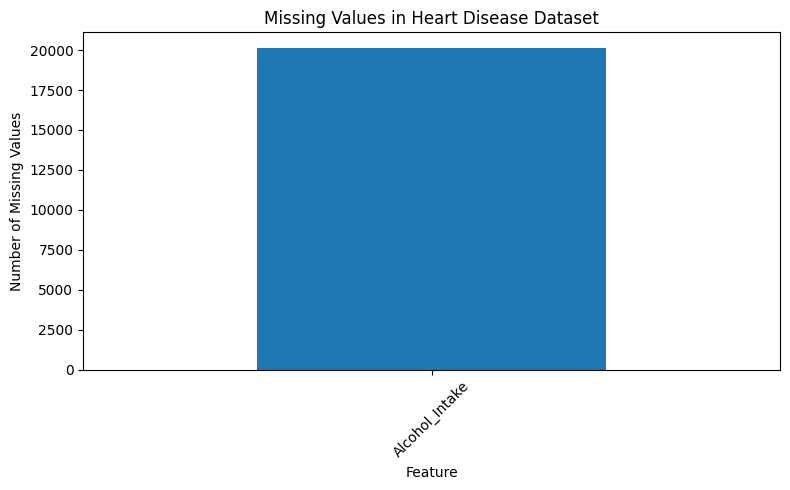

In [ ]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(8, 5))

missing_values.plot(kind="bar")

plt.title("Missing Values in Heart Disease Dataset")
plt.xlabel("Feature")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df["Alcohol_Intake"] = df["Alcohol_Intake"].fillna("Unknown")

In [ ]:
print(df["Alcohol_Intake"].value_counts())

Alcohol_Intake
Unknown     20109
Low         14913
Moderate     9895
High         5083
Name: count, dtype: int64


In [ ]:
print(df.isnull().sum())

Age                      0
Gender                   0
Weight                   0
Height                   0
BMI                      0
Smoking                  0
Alcohol_Intake           0
Physical_Activity        0
Diet                     0
Stress_Level             0
Hypertension             0
Diabetes                 0
Hyperlipidemia           0
Family_History           0
Previous_Heart_Attack    0
Systolic_BP              0
Diastolic_BP             0
Heart_Rate               0
Blood_Sugar_Fasting      0
Cholesterol_Total        0
Heart_Disease            0
dtype: int64


In [ ]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [ ]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


 Age
[48 35 79 75 34 50 67 51 54 74 38 65 59 76 60 39 63 45 37 77]

 Gender
['Male' 'Female']

 Weight
[ 78  73  88 106  65 116  93  75 105  52 110  80  95  89  99  83  76  90
  64 111]

 Height
[157 163 152 171 191 186 158 176 189 197 160 180 172 174 193 155 169 168
 196 167]

 BMI
[26.4 33.  32.3 37.4 18.5 25.3 22.3 18.2 19.6 35.7 34.7 23.8 22.1 33.4
 35.1 30.1 27.4 34.9 24.7 28.1]

 Smoking
['Never' 'Current' 'Former']

 Alcohol_Intake
['Unknown' 'Low' 'Moderate' 'High']

 Physical_Activity
['Sedentary' 'Active' 'Moderate']

 Diet
['Healthy' 'Average' 'Unhealthy']

 Stress_Level
['Medium' 'High' 'Low']

 Hypertension
[0 1]

 Diabetes
[0 1]

 Hyperlipidemia
[1 0]

 Family_History
[1 0]

 Previous_Heart_Attack
[0 1]

 Systolic_BP
[104 111 116 171 164 153 117 114 106 176 169 107 131 155 136 139 128 144
 170 124]

 Diastolic_BP
[ 99  72 102  92  67  91  82  63  97  69  75 107  81  87  77  73  90  79
  95 111]

 Heart_Rate
[ 71  60  78 109 108 106  85  89  75  87  67  84 103  95  69  72

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,50000.0,54.464060,14.438090,30.0,42.0,54.0,67.0,79.0
Weight,50000.0,84.547520,20.213257,50.0,67.0,85.0,102.0,119.0
Height,50000.0,174.460000,14.420379,150.0,162.0,174.0,187.0,199.0
BMI,50000.0,28.984284,6.367494,18.0,23.5,29.0,34.5,40.0
Hypertension,50000.0,0.299620,0.458096,0.0,0.0,0.0,1.0,1.0
Diabetes,50000.0,0.199260,0.399448,0.0,0.0,0.0,0.0,1.0
Hyperlipidemia,50000.0,0.251660,0.433971,0.0,0.0,0.0,1.0,1.0
Family_History,50000.0,0.400500,0.490005,0.0,0.0,0.0,1.0,1.0
Previous_Heart_Attack,50000.0,0.099280,0.299041,0.0,0.0,0.0,0.0,1.0
Systolic_BP,50000.0,139.299580,23.083544,100.0,119.0,139.0,159.0,179.0


In [ ]:
print("Age below 0:", (df["Age"] < 0).sum())
print("Weight below 0:", (df["Weight"] <= 0).sum())
print("Height below 0:", (df["Height"] <= 0).sum())
print("BMI below 0:", (df["BMI"] <= 0).sum())
print("Systolic BP below 0:", (df["Systolic_BP"] <= 0).sum())
print("Diastolic BP below 0:", (df["Diastolic_BP"] <= 0).sum())
print("Heart rate below 0:", (df["Heart_Rate"] <= 0).sum())
print("Blood sugar below 0:", (df["Blood_Sugar_Fasting"] <= 0).sum())
print("Cholesterol below 0:", (df["Cholesterol_Total"] <= 0).sum())

Age below 0: 0
Weight below 0: 0
Height below 0: 0
BMI below 0: 0
Systolic BP below 0: 0
Diastolic BP below 0: 0
Heart rate below 0: 0
Blood sugar below 0: 0
Cholesterol below 0: 0


In [ ]:
binary_columns = [
    "Hypertension",
    "Diabetes",
    "Hyperlipidemia",
    "Family_History",
    "Previous_Heart_Attack",
    "Heart_Disease"
]

for col in binary_columns:
    print(col, df[col].unique())

Hypertension [0 1]
Diabetes [0 1]
Hyperlipidemia [1 0]
Family_History [1 0]
Previous_Heart_Attack [0 1]
Heart_Disease [0 1]


In [ ]:
print(df["Heart_Disease"].value_counts())

Heart_Disease
0    26827
1    23173
Name: count, dtype: int64


In [ ]:
print(
    df["Heart_Disease"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Heart_Disease
0    53.65
1    46.35
Name: proportion, dtype: float64


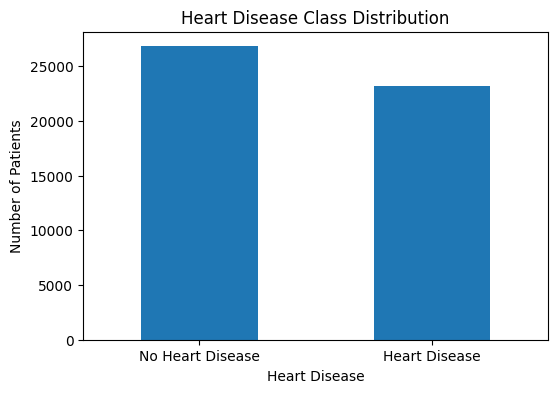

In [ ]:
plt.figure(figsize=(6, 4))
df["Heart_Disease"].value_counts().plot(kind="bar")
plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")
plt.xticks(
    ticks=[0, 1],
    labels=["No Heart Disease", "Heart Disease"],
    rotation=0
)
plt.show()

In [ ]:
categorical_columns = [
    "Gender",
    "Smoking",
    "Alcohol_Intake",
    "Physical_Activity",
    "Diet",
    "Stress_Level"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 Gender
Gender
Female    25110
Male      24890
Name: count, dtype: int64

 Smoking
Smoking
Never      30160
Current     9965
Former      9875
Name: count, dtype: int64

 Alcohol_Intake
Alcohol_Intake
Unknown     20109
Low         14913
Moderate     9895
High         5083
Name: count, dtype: int64

 Physical_Activity
Physical_Activity
Moderate     24976
Sedentary    15077
Active        9947
Name: count, dtype: int64

 Diet
Diet
Average      25169
Healthy      14975
Unhealthy     9856
Name: count, dtype: int64

 Stress_Level
Stress_Level
Medium    20133
Low       19941
High       9926
Name: count, dtype: int64


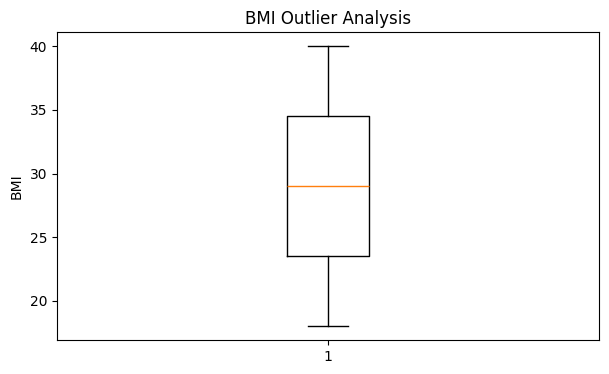

In [ ]:
plt.figure(figsize=(7, 4))
plt.boxplot(df["BMI"])
plt.title("BMI Outlier Analysis")
plt.ylabel("BMI")
plt.show()

/tmp/ipykernel_679/401154396.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


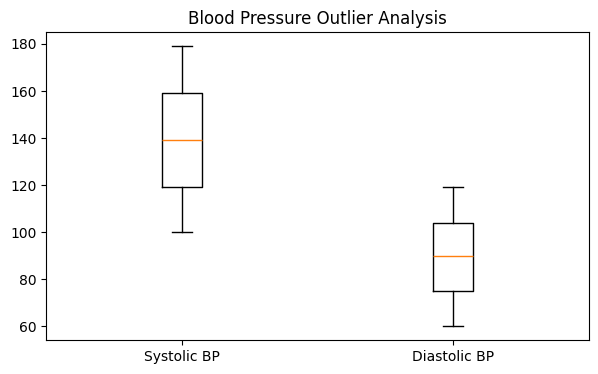

In [ ]:
plt.figure(figsize=(7, 4))
plt.boxplot(
    [df["Systolic_BP"], df["Diastolic_BP"]],
    labels=["Systolic BP", "Diastolic BP"]
)
plt.title("Blood Pressure Outlier Analysis")
plt.show()

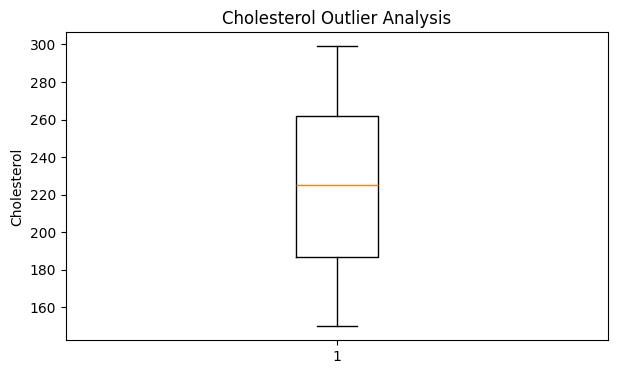

In [ ]:
plt.figure(figsize=(7, 4))
plt.boxplot(df["Cholesterol_Total"])
plt.title("Cholesterol Outlier Analysis")
plt.ylabel("Cholesterol")
plt.show()

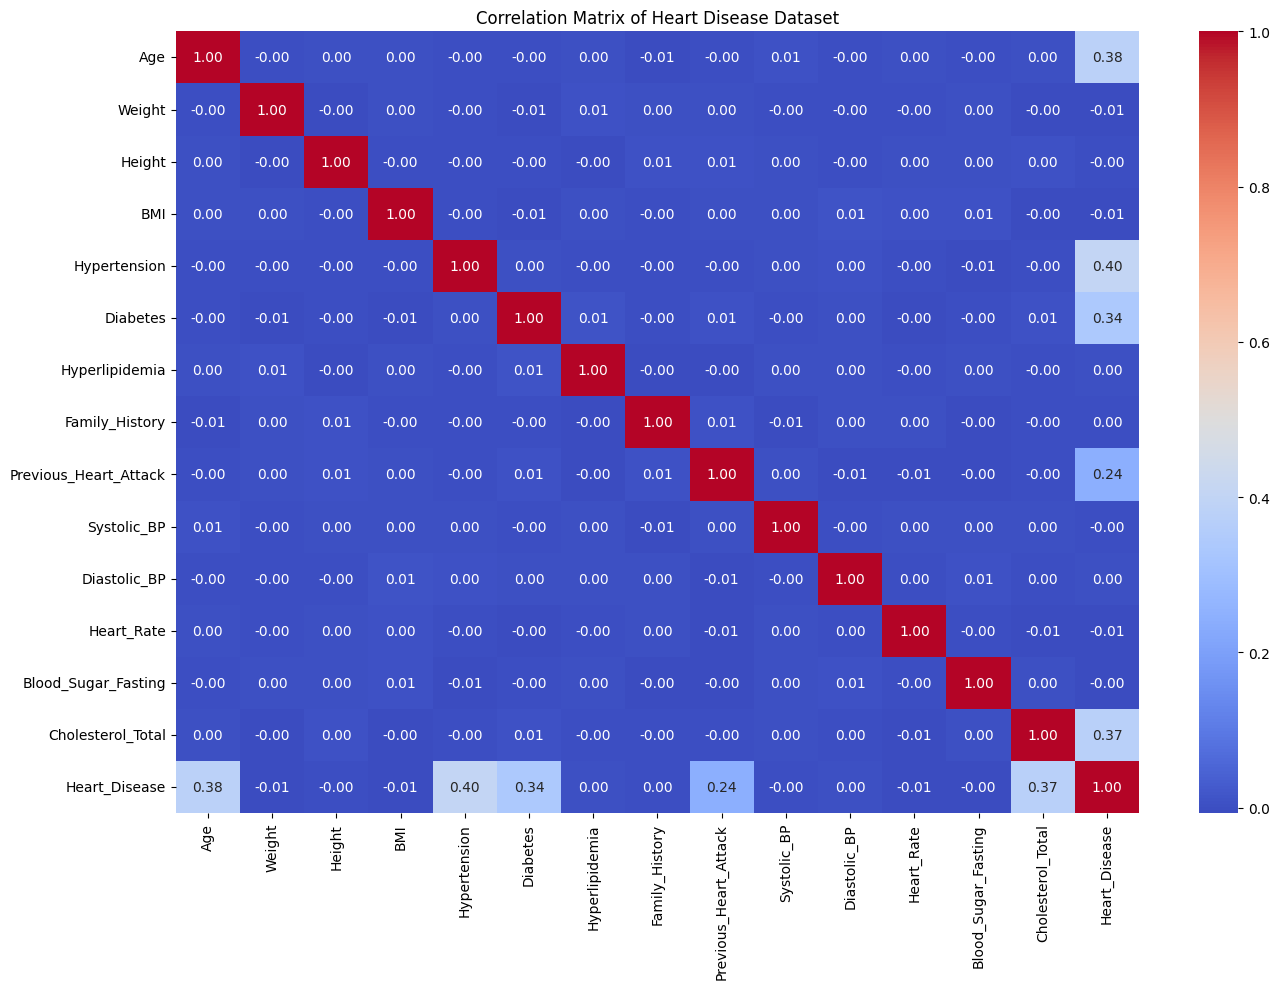

In [ ]:
plt.figure(figsize=(14, 10))
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Matrix of Heart Disease Dataset")
plt.tight_layout()
plt.show()

In [ ]:
calculated_bmi = (
    df["Weight"] /
    ((df["Height"] / 100) ** 2)
)
difference = abs(df["BMI"] - calculated_bmi)
print("Maximum BMI difference:", difference.max())
print("Average BMI difference:", difference.mean())

Maximum BMI difference: 34.888888888888886
Average BMI difference: 8.53477442586598


In [ ]:
for col in categorical_columns:
    print("\n" + col)
    print(sorted(df[col].dropna().unique()))


Gender
['Female', 'Male']

Smoking
['Current', 'Former', 'Never']

Alcohol_Intake
['High', 'Low', 'Moderate', 'Unknown']

Physical_Activity
['Active', 'Moderate', 'Sedentary']

Diet
['Average', 'Healthy', 'Unhealthy']

Stress_Level
['High', 'Low', 'Medium']


In [ ]:
cleaned_file = "heart_disease_cleaned.csv"
df.to_csv(cleaned_file, index=False)
print("Cleaned dataset saved as:", cleaned_file)

Cleaned dataset saved as: heart_disease_cleaned.csv


In [ ]:
calculated_bmi = df["Weight"] / ((df["Height"] / 100) ** 2)
bmi_difference = abs(df["BMI"] - calculated_bmi)
print("Maximum BMI difference:", bmi_difference.max())
print("Average BMI difference:", bmi_difference.mean())
significant_difference = (bmi_difference > 1).mean() * 100
print("Percentage of rows with BMI difference > 1:",round(significant_difference, 2), "%")

Maximum BMI difference: 34.888888888888886
Average BMI difference: 8.53477442586598
Percentage of rows with BMI difference > 1: 92.76 %


In [ ]:
calculated_bmi = df["Weight"] / ((df["Height"] / 100) ** 2)
difference = abs(df["BMI"] - calculated_bmi)
print("Maximum difference:", difference.max())
print("Average difference:", difference.mean())

,Weight,Height,Original_BMI,Calculated_BMI,Difference
11725,119,150,18.0,52.89,34.89
2524,119,150,18.2,52.89,34.69
39925,118,150,18.0,52.44,34.44
15122,119,151,18.1,52.19,34.09
48907,119,151,18.3,52.19,33.89
43364,119,150,19.3,52.89,33.59
43168,119,151,18.6,52.19,33.59
10435,117,150,18.5,52.00,33.50
28874,119,151,18.9,52.19,33.29
17896,118,151,18.5,51.75,33.25


In [ ]:
bmi_check = pd.DataFrame({
    "Weight": df["Weight"],
    "Height": df["Height"],
    "Original_BMI": df["BMI"],
    "Calculated_BMI": calculated_bmi.round(2),
    "Difference": bmi_difference.round(2)
})
bmi_check.sort_values("Difference", ascending=False).head(10)

In [ ]:
calculated_bmi = df["Weight"] / ((df["Height"] / 100) ** 2)
difference = abs(df["BMI"] - calculated_bmi)
print("Maximum difference:", difference.max())
print("Average difference:", difference.mean())

Maximum difference: 0.0
Average difference: 0.0


In [ ]:
original_bmi_corr = df["BMI"].corr(df["Heart_Disease"])
calculated_bmi = df["Weight"] / ((df["Height"] / 100) ** 2)
calculated_bmi_corr = calculated_bmi.corr(df["Heart_Disease"])
print("Original BMI correlation:", round(original_bmi_corr, 4))
print("Calculated BMI correlation:", round(calculated_bmi_corr, 4))

Original BMI correlation: -0.0039
Calculated BMI correlation: -0.0039


In [ ]:
df["BMI"] = df["Weight"] / ((df["Height"] / 100) ** 2)
df["BMI"] = df["BMI"].round(2)
df[["Weight", "Height", "BMI"]].head(10)

,Weight,Height,BMI
0,78,157,31.64
1,73,163,27.48
2,88,152,38.09
3,106,171,36.25
4,65,191,17.82
5,116,186,33.53
6,93,158,37.25
7,75,176,24.21
8,105,189,29.39
9,106,197,27.31


In [ ]:
calculated_bmi = df["Weight"] / ((df["Height"] / 100) ** 2)
difference = abs(df["BMI"] - calculated_bmi)
print("Maximum BMI difference:", difference.max())
print("Average BMI difference:", difference.mean())

Maximum BMI difference: 0.0049999999999954525
Average BMI difference: 0.0025248814061429006


In [ ]:
pd.crosstab(
    df["Previous_Heart_Attack"],
    df["Heart_Disease"],
    normalize="index"
).round(3)

Heart_Disease,0,1
Previous_Heart_Attack,,
0,0.577,0.423
1,0.171,0.829


In [ ]:
pd.crosstab(
    df["Previous_Heart_Attack"],
    df["Heart_Disease"]
)

Heart_Disease,0,1
Previous_Heart_Attack,,
0,25979,19057
1,848,4116


In [ ]:
df["Alcohol_Intake"] = df["Alcohol_Intake"].fillna("Unknown")
df["BMI"] = df["Weight"] / ((df["Height"] / 100) ** 2)
df["BMI"] = df["BMI"].round(2)
df = df.drop_duplicates().reset_index(drop=True)
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nFinal dataset shape:", df.shape)
display(df.head())

Missing values:
Age                      0
Gender                   0
Weight                   0
Height                   0
BMI                      0
Smoking                  0
Alcohol_Intake           0
Physical_Activity        0
Diet                     0
Stress_Level             0
Hypertension             0
Diabetes                 0
Hyperlipidemia           0
Family_History           0
Previous_Heart_Attack    0
Systolic_BP              0
Diastolic_BP             0
Heart_Rate               0
Blood_Sugar_Fasting      0
Cholesterol_Total        0
Heart_Disease            0
dtype: int64

Duplicate rows: 0

Final dataset shape: (50000, 21)


,Age,Gender,Weight,Height,BMI,Smoking,Alcohol_Intake,Physical_Activity,Diet,Stress_Level,...,Diabetes,Hyperlipidemia,Family_History,Previous_Heart_Attack,Systolic_BP,Diastolic_BP,Heart_Rate,Blood_Sugar_Fasting,Cholesterol_Total,Heart_Disease
0,48,Male,78,157,31.64,Never,Unknown,Sedentary,Healthy,Medium,...,0,1,1,0,104,99,71,165,200,0
1,35,Female,73,163,27.48,Never,Low,Active,Average,High,...,0,1,1,0,111,72,60,145,206,0
2,79,Female,88,152,38.09,Never,Unknown,Moderate,Average,Medium,...,0,0,1,0,116,102,78,148,208,0
3,75,Male,106,171,36.25,Never,Moderate,Moderate,Average,Low,...,0,1,0,0,171,92,109,105,290,1
4,34,Female,65,191,17.82,Current,Unknown,Sedentary,Healthy,Low,...,1,0,0,0,164,67,108,116,220,1


In [ ]:
df.to_csv("heart_disease_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
import os
print(os.path.exists("heart_disease_cleaned.csv"))

True


In [ ]:
df.to_csv("heart_disease_cleaned.csv", index=False)

In [ ]:
X = df.drop(columns=["Heart_Disease"])
y = df["Heart_Disease"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (50000, 20)
Target shape: (50000,)


In [ ]:
categorical_columns = [
    "Gender",
    "Smoking",
    "Alcohol_Intake",
    "Physical_Activity",
    "Diet",
    "Stress_Level"
]

X_encoded = pd.get_dummies(X, columns=categorical_columns, drop_first=True)

print("Shape after encoding:", X_encoded.shape)
X_encoded.head()

Shape after encoding: (50000, 26)


,Age,Weight,Height,BMI,Hypertension,Diabetes,Hyperlipidemia,Family_History,Previous_Heart_Attack,Systolic_BP,...,Smoking_Never,Alcohol_Intake_Low,Alcohol_Intake_Moderate,Alcohol_Intake_Unknown,Physical_Activity_Moderate,Physical_Activity_Sedentary,Diet_Healthy,Diet_Unhealthy,Stress_Level_Low,Stress_Level_Medium
0,48,78,157,31.64,0,0,1,1,0,104,...,True,False,False,True,False,True,True,False,False,True
1,35,73,163,27.48,1,0,1,1,0,111,...,True,True,False,False,False,False,False,False,False,False
2,79,88,152,38.09,0,0,0,1,0,116,...,True,False,False,True,True,False,False,False,False,True
3,75,106,171,36.25,0,0,1,0,0,171,...,True,False,True,False,True,False,False,False,True,False
4,34,65,191,17.82,1,1,0,0,0,164,...,False,False,False,True,False,True,True,False,True,False


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (40000, 26)
Test shape: (10000, 26)


In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_columns = [
    "Age", "Weight", "Height", "BMI",
    "Systolic_BP", "Diastolic_BP", "Heart_Rate",
    "Blood_Sugar_Fasting", "Cholesterol_Total"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test_scaled[numeric_columns] = scaler.transform(X_test[numeric_columns])

X_train_scaled.head()

,Age,Weight,Height,BMI,Hypertension,Diabetes,Hyperlipidemia,Family_History,Previous_Heart_Attack,Systolic_BP,...,Smoking_Never,Alcohol_Intake_Low,Alcohol_Intake_Moderate,Alcohol_Intake_Unknown,Physical_Activity_Moderate,Physical_Activity_Sedentary,Diet_Healthy,Diet_Unhealthy,Stress_Level_Low,Stress_Level_Medium
7063,0.311841,1.458385,-0.929666,1.868505,0,0,0,1,1,1.240288,...,False,False,True,False,False,True,False,True,True,False
12319,0.242628,1.656473,-1.622415,2.799086,0,0,1,0,0,1.024019,...,True,False,False,True,False,False,False,False,False,True
28934,-1.418487,0.814598,-0.375467,0.836123,0,0,0,1,0,0.634734,...,True,False,True,False,False,True,False,False,False,True
7460,1.350038,0.814598,-0.514017,0.937924,1,0,0,1,0,0.461719,...,False,False,False,True,False,True,False,True,True,False
47939,-0.657142,-1.067242,-1.691690,-0.045354,0,0,1,0,0,0.677988,...,False,False,True,False,True,False,True,False,True,False


In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1-score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.9239
Precision: 0.9179974104445403
Recall: 0.917799352750809
F1-score: 0.9178983709137987
ROC-AUC: 0.9822063375729262

Confusion Matrix:
 [[4985  380]
 [ 381 4254]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93      5365
           1       0.92      0.92      0.92      4635

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



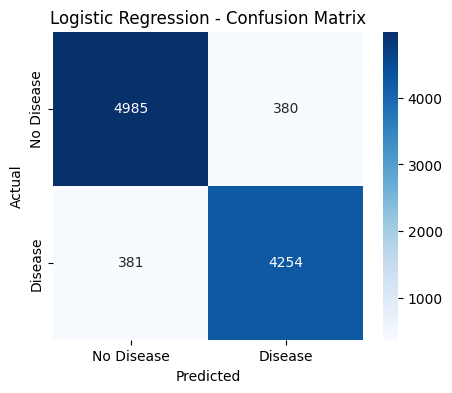

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_lr),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0

Confusion Matrix:
 [[5365    0]
 [   0 4635]]


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_scaled, y_train)

y_pred_gb = gb.predict(X_test_scaled)
y_prob_gb = gb.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1-score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0

Confusion Matrix:
 [[5365    0]
 [   0 4635]]


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
}).round(4)

comparison

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9239,0.918,0.9178,0.9179,0.9822
1,Random Forest,1.0000,1.000,1.0000,1.0000,1.0000
2,Gradient Boosting,1.0000,1.000,1.0000,1.0000,1.0000


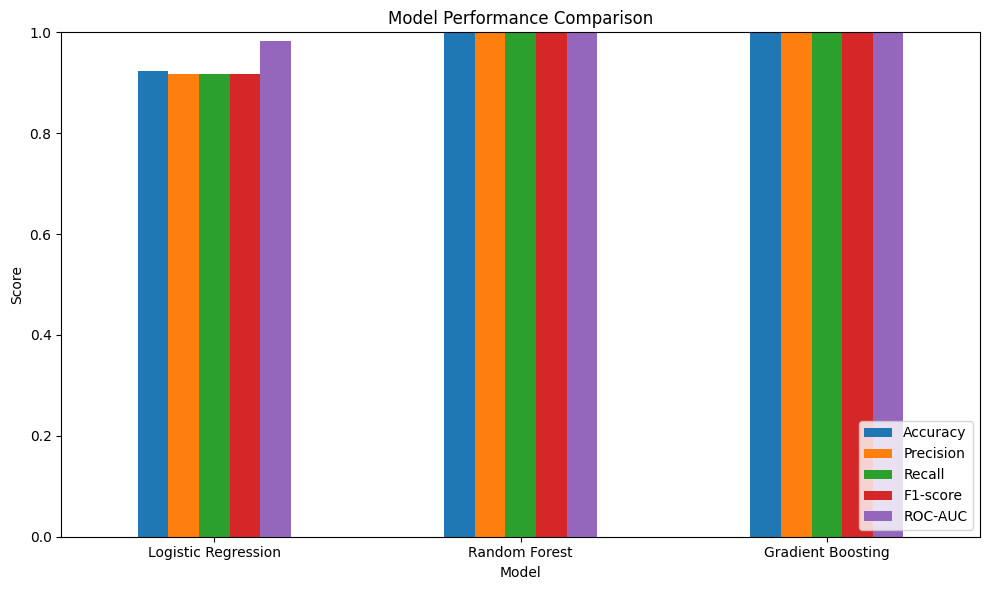

In [ ]:
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

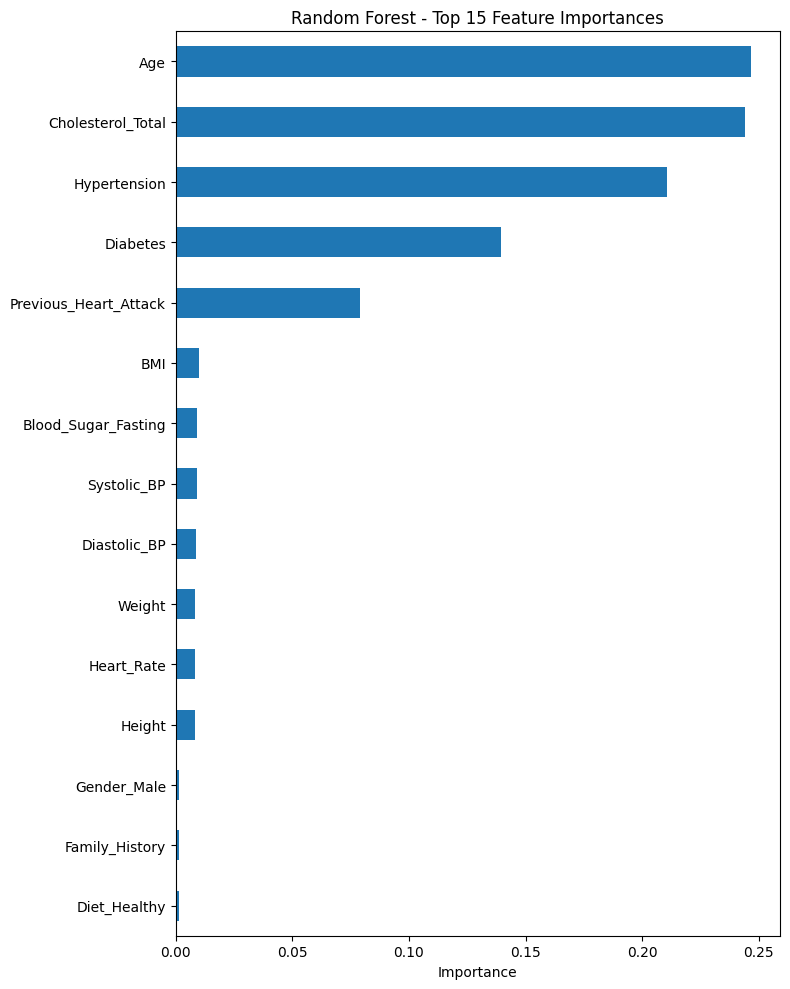

Age                      0.246711
Cholesterol_Total        0.244181
Hypertension             0.210600
Diabetes                 0.139627
Previous_Heart_Attack    0.079199
BMI                      0.010095
Blood_Sugar_Fasting      0.009168
Systolic_BP              0.009068
Diastolic_BP             0.008665
Weight                   0.008400
Heart_Rate               0.008333
Height                   0.008133
Gender_Male              0.001462
Family_History           0.001451
Diet_Healthy             0.001352
dtype: float64


In [ ]:
importances = pd.Series(rf.feature_importances_, index=X_train_scaled.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(8, 10))
importances.head(15).plot(kind="barh")
plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(importances.head(15))

In [ ]:
top_feature = importances.index[0]
print("Top feature:", top_feature)

print(pd.crosstab(df[top_feature] if top_feature in df.columns else X[top_feature], y, normalize="index").round(3))

Top feature: Age
Heart_Disease      0      1
Age                        
30             0.734  0.266
31             0.717  0.283
32             0.759  0.241
33             0.736  0.264
34             0.730  0.270
35             0.746  0.254
36             0.752  0.248
37             0.775  0.225
38             0.727  0.273
39             0.751  0.249
40             0.770  0.230
41             0.762  0.238
42             0.769  0.231
43             0.764  0.236
44             0.770  0.230
45             0.728  0.272
46             0.740  0.260
47             0.766  0.234
48             0.719  0.281
49             0.766  0.234
50             0.737  0.263
51             0.721  0.279
52             0.747  0.253
53             0.744  0.256
54             0.747  0.253
55             0.725  0.275
56             0.295  0.705
57             0.327  0.673
58             0.322  0.678
59             0.325  0.675
60             0.265  0.735
61             0.327  0.673
62             0.292  0.708
63 